# AP4: Enumeration eines kleinen Falls (Issue #13, R-49)

Für eine einzelne Entscheidungssituation werden **alle zulässigen Chargenbildungen** aufgezählt,
bewertet und mit den Entscheidungen der Verfahren V1 bis V3 verglichen. V4 folgt, sobald das Team
den Kandidaten gewählt hat (Issue #12).

Die Logik steht in `src/matsim/regeln/enumeration.py` (Tests: `tests/test_regeln_enumeration.py`).
Das Notebook ruft sie nur auf und zeigt die Ergebnisse.

**Entscheidungshorizont:** genau eine Entscheidung zum Zeitpunkt 0 s. Alle offenen Sätze sind bekannt,
künftige Bedarfe nicht. Jede Alternative bindet alle Sätze und versendet sofort; ohne neue Bedarfe
bringt Warten nur Verzögerung. Verfahren, die warten (V2, V3), werden über ihre angemeldeten
Wartefristen weitergeführt, bis alle Sätze gebunden sind.

**Wichtig für die Hausarbeit:** Eine optimale Einzelentscheidung beweist keinen insgesamt optimalen
Ablauf. Die Enumeration zeigt, wie gut eine Regel *im Kleinen* entscheidet.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from matsim.modell.anlage import lade_anlage
from matsim.modell.typen import Anforderung, Materialsatz
from matsim.regeln.basis import Planungszustand
from matsim.regeln.enumeration import (
    Zeitansaetze,
    alternativen,
    aufteilungen,
    bewerte,
    pareto_front,
    plan_des_verfahrens,
)
from matsim.regeln.verfahren import erzeuge

anlage = lade_anlage()
ZEITEN = Zeitansaetze.aus_anlage(anlage)
ZULAESSIG = {
    name: frozenset(st["zulaessige_teile"]["wert"]) for name, st in anlage["stationen"].items()
}
SATZ = {
    name: tuple((pno, p["wert"]) for pno, p in st["materialsatz"].items())
    for name, st in anlage["stationen"].items()
}
ANFANGSBESTAND = {pno: p["wert"] for pno, p in anlage["materiallager"]["anfangsbestand"].items()}
BOXEN = anlage["box"]["transportboxen_frei"]["wert"]
POSITIONEN = anlage["box"]["positionen"]["wert"]

# Verfahren mit Beispielparametern; die endgültigen Werte legt Issue #14 auf `kalibrierung` fest.
VERFAHREN = {
    "V1": {},
    "V2": {"fuellschwelle_positionen": 8, "hoechstwartezeit_s": 600},
    "V3": {"max_wartezeit_s": 300},
}
ZEITEN

Zeitansaetze(vorlauf_s=264, pickzeit_je_teil_s=23, quellboxwechsel_s=62, hintransport_s=130)

## Bewertungsmodell und Zielgrößen

Das Modell ist bewusst einfach, damit jede Alternative von Hand nachgerechnet werden kann
(Beispiel im Test `test_bewertung_von_hand_nachgerechnet`):

- Der Kommissionierplatz bearbeitet **eine Charge zur Zeit** (A-04), in der Reihenfolge der Alternative.
- Dauer einer Charge = `vorlauf_s + Teile × pickzeit_je_teil_s + (Quellboxen − 1) × quellboxwechsel_s`
  (Formel aus `config/anlage.yaml`, A-11). Als Zahl der Quellboxen gilt die Zahl verschiedener
  Teilenummern der Charge (**Annahme der Enumeration**, an AP2 zu melden).
- Danach Hintransport mit `hintransport_s` (enthält Warten auf ein Fahrzeug, A-07).
- Nicht modelliert: Fahrzeuge als Ressource, Übergabeplätze, Montage, Leerboxrückführung.

Zielgrößen:

1. **Transporte**: Zahl der Boxen.
2. **Ø Bereitstellungszeit**: mittlere Zeit vom Entscheidungszeitpunkt bis zur Lieferung eines Satzes.
3. **Max. Bereitstellungszeit**: Zeit bis zur Lieferung des letzten Satzes.

Eine Alternative ist **Pareto-optimal**, wenn keine andere bei Transporten und Ø-Zeit mindestens so gut
und in einer Größe besser ist. Eine Gewichtung der Ziele legt das Team fest (Zielhierarchie,
`planungsverfahren.md`, Abschnitt 2).

In [2]:
def anforderung(id_, station, eingang_s):
    return Anforderung(
        id_, station, 1, 1, eingang_s, eingang_s + 600.0, Materialsatz(id_, station, SATZ[station])
    )


def zustand(anforderungen, bestand=ANFANGSBESTAND):
    return Planungszustand(
        zeit_s=0.0,
        offene_anforderungen=tuple(anforderungen),
        freier_bestand=dict(bestand),
        freie_boxen=BOXEN,
        freie_kommissionierplaetze=1,
        freie_fahrzeuge=2,
        freie_uebergabeplaetze={name: 2 for name in ZULAESSIG},
        box_positionen=POSITIONEN,
        zulaessige_teile=ZULAESSIG,
    )


def text(folge):
    return " | ".join("+".join(c.anforderung_ids) for c in folge)


def auswerten(z, zeiten=ZEITEN):
    alle = list(alternativen(z))
    bewertungen = [bewerte(a, z, zeiten) for a in alle]
    front = set(pareto_front(bewertungen))
    tabelle = pd.DataFrame(
        {
            "Kommissionierfolge": [text(a) for a in alle],
            "Transporte": [b.transporte for b in bewertungen],
            "Ø Bereitstellung s": [round(b.mittlere_bereitstellung_s, 1) for b in bewertungen],
            "Max. Bereitstellung s": [b.max_bereitstellung_s for b in bewertungen],
            "Pareto-optimal": [i in front for i in range(len(alle))],
        }
    )
    verfahren = []
    for name, parameter in VERFAHREN.items():
        plan = plan_des_verfahrens(erzeuge(name, **parameter), z)
        b = bewerte(plan, z, zeiten)
        verfahren.append(
            {
                "Verfahren": name,
                "Chargen (Bindungszeitpunkt)": " | ".join(
                    f"{'+'.join(c.anforderung_ids)} ({c.versand_fruehestens_s:.0f} s)" for c in plan
                ),
                "Transporte": b.transporte,
                "Ø Bereitstellung s": round(b.mittlere_bereitstellung_s, 1),
                "Max. Bereitstellung s": b.max_bereitstellung_s,
            }
        )
    print(f"Aufteilungen auf Boxen (ohne Reihenfolge): {len(aufteilungen(z))}")
    print(f"Alternativen mit Kommissionierreihenfolge:  {len(alle)}")
    return tabelle, pd.DataFrame(verfahren)


def beste_je_transportzahl(tabelle):
    idx = tabelle.groupby("Transporte")["Ø Bereitstellung s"].idxmin()
    return tabelle.loc[idx].reset_index(drop=True)


def zeichne(tabelle, verfahren, titel):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.scatter(
        tabelle["Transporte"],
        tabelle["Ø Bereitstellung s"],
        s=12,
        alpha=0.3,
        color="grey",
        label="Alternative",
    )
    front = tabelle[tabelle["Pareto-optimal"]]
    ax.scatter(
        front["Transporte"],
        front["Ø Bereitstellung s"],
        s=40,
        color="black",
        label="Pareto-optimal",
    )
    for nr, (_, zeile) in enumerate(verfahren.iterrows()):
        ax.scatter(
            zeile["Transporte"],
            zeile["Ø Bereitstellung s"],
            s=90,
            marker="os^"[nr],
            facecolors="none",
            edgecolors=f"C{nr}",
            linewidths=2,
            label=zeile["Verfahren"],
        )
    ax.set_xlabel("Transporte (Boxen)")
    ax.set_ylabel("Ø Bereitstellungszeit in s")
    ax.set_title(titel)
    ax.set_xticks(sorted(tabelle["Transporte"].unique()))
    ax.legend(loc="best", fontsize=8)
    plt.show()

## Fall 1: fünf Sätze an zwei Stationen

Drei Sätze für RASS1 (je 800 + 814, also 2 Positionen) und zwei für RASS3 (je 831, 1 Position),
eingegangen zwischen −120 s und 0 s. Bestand und Boxen aus `config/anlage.yaml` reichen.

Zahl der Alternativen: Je Station gibt es so viele Aufteilungen wie Mengenpartitionen
(Bellzahlen B(3) = 5 für RASS1, B(2) = 2 für RASS3), zusammen 10. Mit allen Reihenfolgen am
Kommissionierplatz werden es 242.

In [3]:
fall_1 = zustand(
    [
        anforderung("A1", "RASS1", -120),
        anforderung("A2", "RASS1", -60),
        anforderung("A3", "RASS1", 0),
        anforderung("B1", "RASS3", -90),
        anforderung("B2", "RASS3", 0),
    ]
)
tabelle_1, verfahren_1 = auswerten(fall_1)
beste_je_transportzahl(tabelle_1)

Aufteilungen auf Boxen (ohne Reihenfolge): 10
Alternativen mit Kommissionierreihenfolge:  242


,Kommissionierfolge,Transporte,Ø Bereitstellung s,Max. Bereitstellung s,Pareto-optimal
0,A1+A2+A3 | B1+B2,2,718.0,904.0,True
1,B1+B2 | A1+A2 | A3,3,765.2,1230.0,False
2,B1+B2 | A1 | A2 | A3,4,886.4,1556.0,False
3,B1 | B2 | A1 | A2 | A3,5,1093.0,1820.0,False


In [4]:
verfahren_1

,Verfahren,Chargen (Bindungszeitpunkt),Transporte,Ø Bereitstellung s,Max. Bereitstellung s
0,V1,A1 (0 s) | B1 (0 s) | A2 (0 s) | A3 (0 s) | B2...,5,1161.0,1820.0
1,V2,A1+A2+A3 (480 s) | B1+B2 (510 s),2,1198.0,1384.0
2,V3,A1+A2+A3 (180 s) | B1+B2 (210 s),2,898.0,1084.0


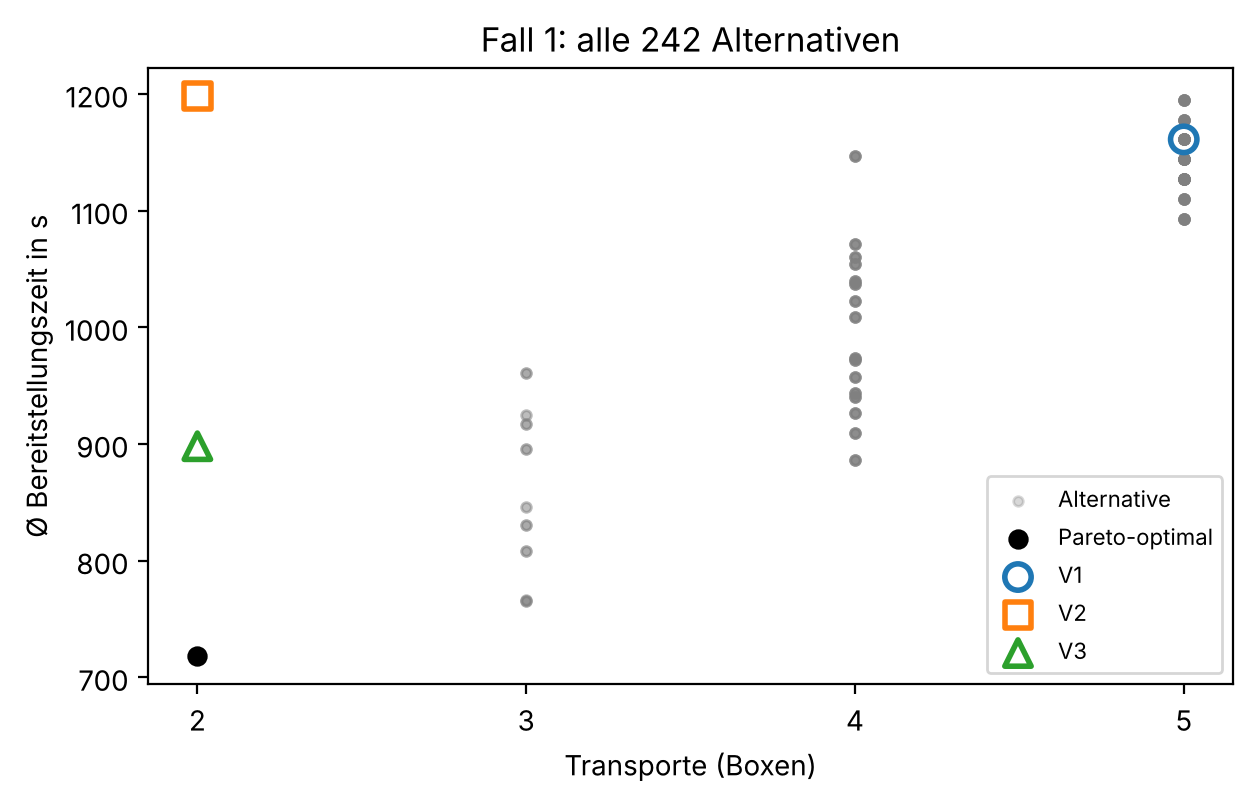

In [5]:
zeichne(tabelle_1, verfahren_1, "Fall 1: alle 242 Alternativen")

## Fall 2: Boxkapazität erzwingt eine Teilung

Fünf Sätze für RASS1 (10 Positionen, passen nicht in eine Box) und ein Satz für RASS3. Der Bestand
an 800 und 814 wird für diesen Fall auf 6 gesetzt (Szenarioannahme nur für die Enumeration; der
Anfangsbestand von 4 reicht nicht für fünf RASS1-Sätze, L-11).

In [6]:
fall_2 = zustand(
    [anforderung(f"A{n + 1}", "RASS1", -240 + 60 * n) for n in range(5)]
    + [anforderung("B1", "RASS3", -90)],
    bestand={**ANFANGSBESTAND, 800: 6, 814: 6},
)
tabelle_2, verfahren_2 = auswerten(fall_2)
beste_je_transportzahl(tabelle_2)

Aufteilungen auf Boxen (ohne Reihenfolge): 51
Alternativen mit Kommissionierreihenfolge:  2610


,Kommissionierfolge,Transporte,Ø Bereitstellung s,Max. Bereitstellung s,Pareto-optimal
0,A1+A2+A3+A4 | B1 | A5,3,797.7,1299.0,True
1,A1+A2+A3 | B1 | A4 | A5,4,923.5,1625.0,False
2,A1+A2 | B1 | A3 | A4 | A5,5,1111.3,1951.0,False
3,B1 | A1 | A2 | A3 | A4 | A5,6,1347.0,2277.0,False


In [7]:
verfahren_2

,Verfahren,Chargen (Bindungszeitpunkt),Transporte,Ø Bereitstellung s,Max. Bereitstellung s
0,V1,A1 (0 s) | A2 (0 s) | A3 (0 s) | B1 (0 s) | A4...,6,1389.5,2277.0
1,V2,A1+A2+A3+A4 (0 s) | B1 (510 s) | A5 (600 s),3,797.7,1299.0
2,V3,A1+A2+A3+A4 (0 s) | B1 (210 s) | A5 (300 s),3,797.7,1299.0


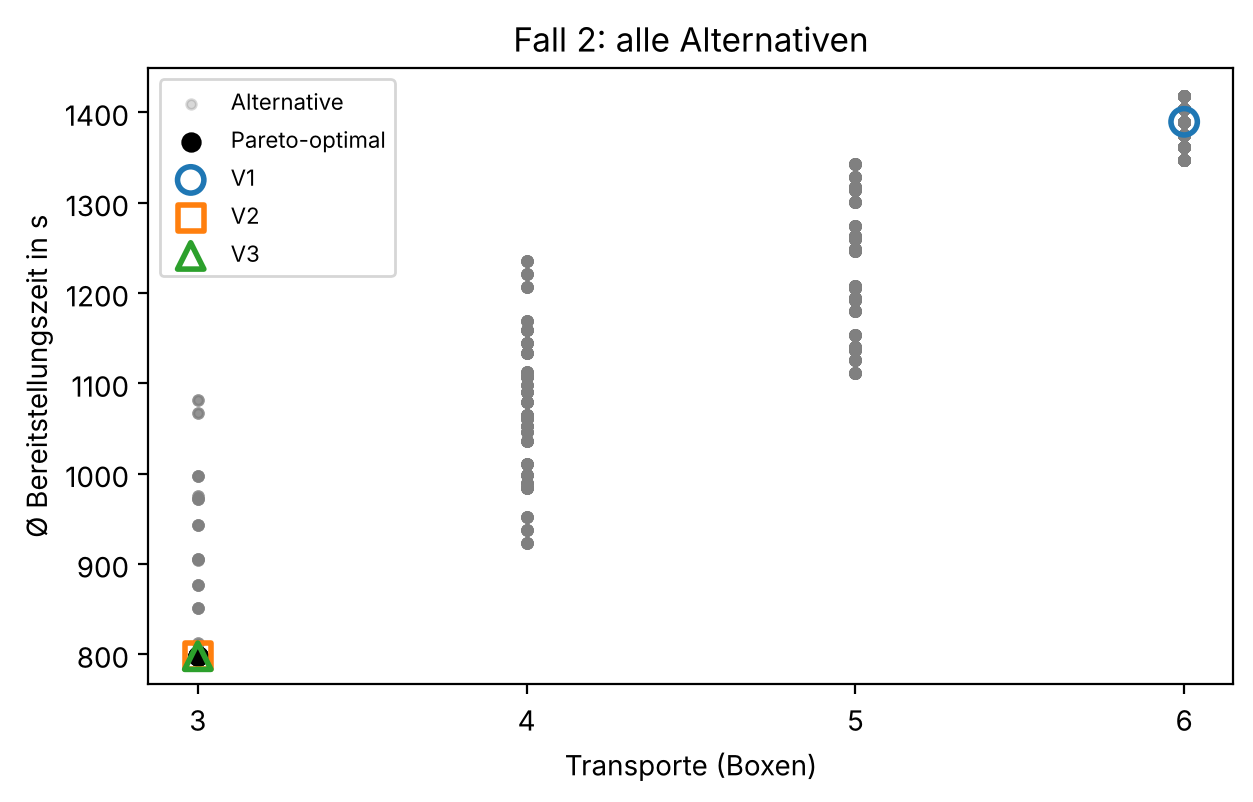

In [8]:
zeichne(tabelle_2, verfahren_2, "Fall 2: alle Alternativen")

## Sensitivität: ohne Vorlauf und Quellboxwechsel

Der Vorlauf von 264 s je Kommissionierauftrag enthält die Bereitstellung von Ziel- und Quellboxen
durch die Robotinos. Werden diese Fahrten später in der Simulation modelliert, fällt er als Festwert weg
(A-11). Zur Einordnung: Fall 1 mit `vorlauf_s = 0` und `quellboxwechsel_s = 0`.

In [9]:
ohne_vorlauf = Zeitansaetze(
    vorlauf_s=0,
    pickzeit_je_teil_s=ZEITEN.pickzeit_je_teil_s,
    quellboxwechsel_s=0,
    hintransport_s=ZEITEN.hintransport_s,
)
tabelle_3, verfahren_3 = auswerten(fall_1, ohne_vorlauf)
beste_je_transportzahl(tabelle_3)

Aufteilungen auf Boxen (ohne Reihenfolge): 10
Alternativen mit Kommissionierreihenfolge:  242


,Kommissionierfolge,Transporte,Ø Bereitstellung s,Max. Bereitstellung s,Pareto-optimal
0,B1+B2 | A1+A2+A3,2,258.8,314.0,True
1,B1+B2 | A1+A2 | A3,3,240.4,314.0,True
2,B1+B2 | A1 | A2 | A3,4,231.2,314.0,True
3,B1 | B2 | A1 | A2 | A3,5,226.6,314.0,True


In [10]:
verfahren_3

,Verfahren,Chargen (Bindungszeitpunkt),Transporte,Ø Bereitstellung s,Max. Bereitstellung s
0,V1,A1 (0 s) | B1 (0 s) | A2 (0 s) | A3 (0 s) | B2...,5,245.0,314.0
1,V2,A1+A2+A3 (480 s) | B1+B2 (510 s),2,766.4,794.0
2,V3,A1+A2+A3 (180 s) | B1+B2 (210 s),2,466.4,494.0


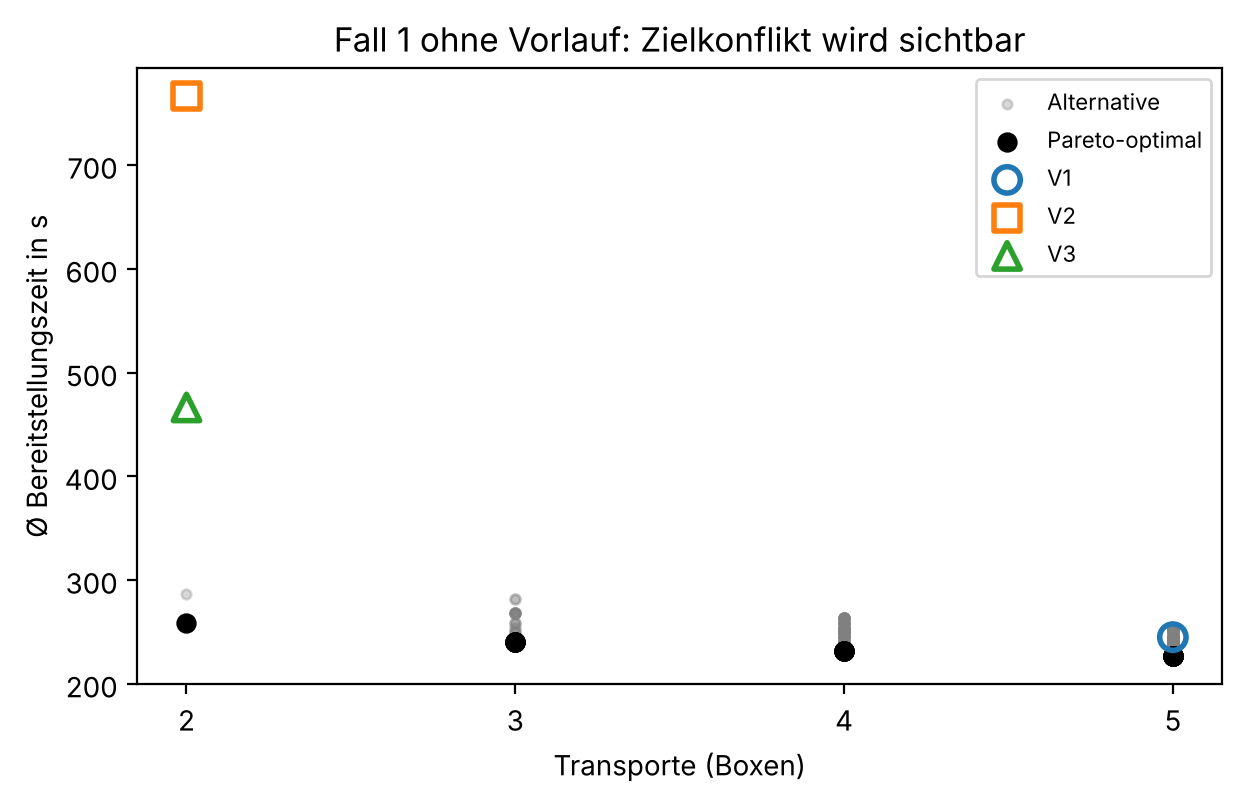

In [11]:
zeichne(tabelle_3, verfahren_3, "Fall 1 ohne Vorlauf: Zielkonflikt wird sichtbar")

## Ergebnis

| | Fall 1 | Fall 2 | Fall 1 ohne Vorlauf |
|---|---|---|---|
| Aufteilungen / Alternativen | 10 / 242 | 51 / 2 610 | 10 / 242 |
| Optimum (Transporte, Ø s) | 2, 718 | 3, 798 | Zielkonflikt: 2, 259 bis 5, 227 |
| V1 | 5, 1 161 | 6, 1 390 | 5, 245 |
| V2 (Schwelle 8, Frist 600 s) | 2, 1 198 | 3, 798 | 2, 766 |
| V3 (Frist 300 s) | 2, 898 | 3, 798 | 2, 466 |

1. **Mit den gemessenen Zeiten gibt es im Kleinen keinen Zielkonflikt.** Der Vorlauf von 264 s fällt je
   Kommissionierauftrag einmal an. Je Station eine Box ist deshalb zugleich die Lösung mit den wenigsten
   Transporten und der kürzesten Bereitstellungszeit. V1 (Lot-for-Lot) liegt in beiden Größen am
   weitesten vom Optimum entfernt.
2. **Die Kosten von V2 und V3 sind das Warten.** Sie finden in Fall 1 die optimale Aufteilung, binden
   sie aber erst zur Frist. Die Ø-Zeit steigt um genau diese Wartezeit (V3: +180 s, V2: +480 s).
3. **Warten ist unschädlich, solange der Kommissionierplatz ohnehin belegt ist.** In Fall 2 warten V2 und
   V3 auf B1 und A5, während die erste Box kommissioniert wird. Beide erreichen das Optimum. Das stützt
   die V4-Kandidaten K2 (rückwärtsterminiert auffüllen) und K3 (engpassabhängig bündeln).
4. **Das Ergebnis hängt am Vorlauf.** Ohne Vorlauf entsteht der erwartete Zielkonflikt: Mehr Boxen
   senken die Ø-Zeit leicht. Dann zählt auch die Reihenfolge. V1 liegt nicht auf der Pareto-Front,
   weil es in Eingangsfolge statt kürzeste Charge zuerst kommissioniert.

**Grenzen:** eine einzige Entscheidung ohne künftige Bedarfe, keine Fahrzeuge als Ressource, keine
Montage, Werkstückankünfte und Bedarfszeitpunkte spielen keine Rolle. Die Parameter von V2 und V3 sind
Beispielwerte. Eine optimale Einzelentscheidung beweist keinen insgesamt optimalen Ablauf; dafür ist der
Simulationsvergleich (AP5) da.

**Annahmen dieses Notebooks** (an AP2 für `annahmen-und-datenluecken.md` zu melden):
- Zahl der Quellboxen einer Charge = Zahl verschiedener Teilenummern.
- Fall 2 setzt den Bestand an 800 und 814 auf 6 (nur Enumeration).